In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv('/content/titanic_cleaned.csv')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape: (775, 14)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 775 entries, 0 to 774
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     775 non-null    int64  
 1   pclass       775 non-null    int64  
 2   sex          775 non-null    object 
 3   age          775 non-null    float64
 4   sibsp        775 non-null    int64  
 5   parch        775 non-null    int64  
 6   fare         775 non-null    float64
 7   embarked     775 non-null    object 
 8   class        775 non-null    object 
 9   who          775 non-null    object 
 10  adult_male   775 non-null    bool   
 11  embark_town  773 non-null    object 
 12  alive        775 non-null    object 
 13  alone        775 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(6)
memory usage: 74.3+ KB

Missing Values:
survived       0
pclass         0
sex            0
age            0
sibsp          0
pa

In [4]:
print("Survival Count:")
print(df['survived'].value_counts())

Survival Count:
survived
0    455
1    320
Name: count, dtype: int64


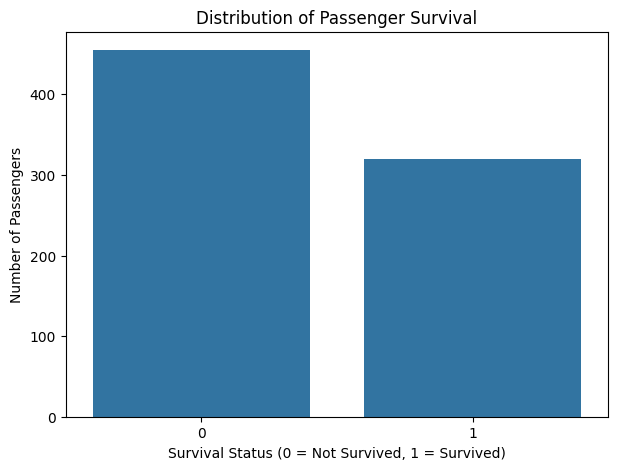

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='survived')

plt.title('Distribution of Passenger Survival')
plt.xlabel('Survival Status (0 = Not Survived, 1 = Survived)')
plt.ylabel('Number of Passengers')

plt.show()

In [6]:
survival_percentage = df['survived'].value_counts(normalize=True) * 100

print("Survival Percentage:")
print(survival_percentage)

Survival Percentage:
survived
0    58.709677
1    41.290323
Name: proportion, dtype: float64


In [7]:
print("Available Columns:")
print(df.columns.tolist())

Available Columns:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone']


In [8]:
features = [
    'pclass',
    'sex',
    'age',
    'sibsp',
    'parch',
    'fare',
    'embarked'
]

X = df[features].copy()
y = df['survived'].copy()

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   pclass     sex   age  sibsp  parch     fare embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Target:
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


In [9]:
print("Shape of Input Features:", X.shape)

print("Shape of Target Variable:", y.shape)

print("\nFeature Data Types:")
print(X.dtypes)

Shape of Input Features: (775, 7)
Shape of Target Variable: (775,)

Feature Data Types:
pclass        int64
sex          object
age         float64
sibsp         int64
parch         int64
fare        float64
embarked     object
dtype: object


In [10]:
print("Missing Values:")
print(X.isnull().sum())

print("\nTotal Missing Values:")
print(X.isnull().sum().sum())

Missing Values:
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

Total Missing Values:
0


In [11]:
print("No missing values found in the selected features.")
print("Data preprocessing check completed successfully.")

No missing values found in the selected features.
Data preprocessing check completed successfully.


In [12]:
X = pd.get_dummies(
    X,
    columns=['sex', 'embarked'],
    drop_first=True,
    dtype=int
)

display(X.head())

,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S
0,3,22.0,1,0,7.2500,1,0,1
1,1,38.0,1,0,71.2833,0,0,0
2,3,26.0,0,0,7.9250,0,0,1
3,1,35.0,1,0,53.1000,0,0,1
4,3,35.0,0,0,8.0500,1,0,1


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (620, 8)
Testing Features: (155, 8)
Training Target: (620,)
Testing Target: (155,)


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

Feature Scaling Completed Successfully!


In [15]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [16]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 77.42 %


In [17]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [18]:
  rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 83.23 %


In [19]:
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION EVALUATION")

print(classification_report(
    y_test,
    lr_predictions,
    target_names=['Not Survived', 'Survived']
))

LOGISTIC REGRESSION EVALUATION
              precision    recall  f1-score   support

Not Survived       0.80      0.81      0.81        91
    Survived       0.73      0.72      0.72        64

    accuracy                           0.77       155
   macro avg       0.77      0.77      0.77       155
weighted avg       0.77      0.77      0.77       155



In [20]:
print("RANDOM FOREST EVALUATION")

print(classification_report(
    y_test,
    rf_predictions,
    target_names=['Not Survived', 'Survived']
))

RANDOM FOREST EVALUATION
              precision    recall  f1-score   support

Not Survived       0.84      0.89      0.86        91
    Survived       0.83      0.75      0.79        64

    accuracy                           0.83       155
   macro avg       0.83      0.82      0.82       155
weighted avg       0.83      0.83      0.83       155



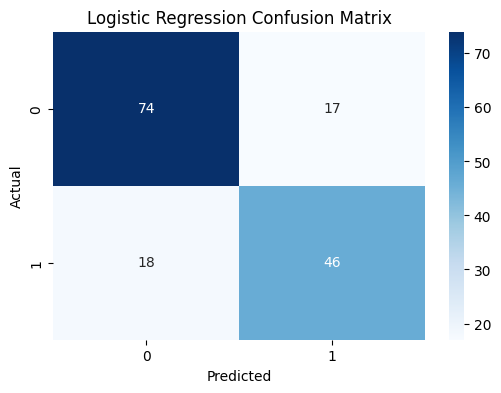

In [21]:
from sklearn.metrics import confusion_matrix

cm_lr = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

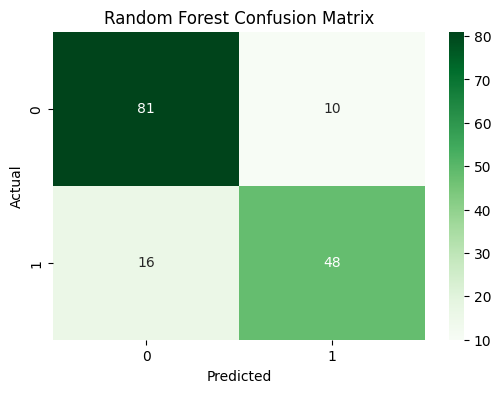

In [22]:
cm_rf = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [23]:
from sklearn.model_selection import cross_val_score

lr_cv_scores = cross_val_score(
    lr_model,
    X_train_scaled,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Logistic Regression CV Scores:")
print(lr_cv_scores)

print("Mean CV Accuracy:",
      round(lr_cv_scores.mean() * 100, 2), "%")

Logistic Regression CV Scores:
[0.73387097 0.71774194 0.75       0.82258065 0.77419355]
Mean CV Accuracy: 75.97 %


In [24]:
rf_cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Random Forest CV Scores:")
print(rf_cv_scores)

print("Mean CV Accuracy:",
      round(rf_cv_scores.mean() * 100, 2), "%")

Random Forest CV Scores:
[0.79032258 0.75806452 0.78225806 0.77419355 0.77419355]
Mean CV Accuracy: 77.58 %


In [25]:
comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest'
    ],
    'Test Accuracy': [
        lr_accuracy,
        rf_accuracy
    ],
    'Cross Validation Accuracy': [
        lr_cv_scores.mean(),
        rf_cv_scores.mean()
    ]
})

display(comparison)

,Model,Test Accuracy,Cross Validation Accuracy
0,Logistic Regression,0.774194,0.759677
1,Random Forest,0.832258,0.775806


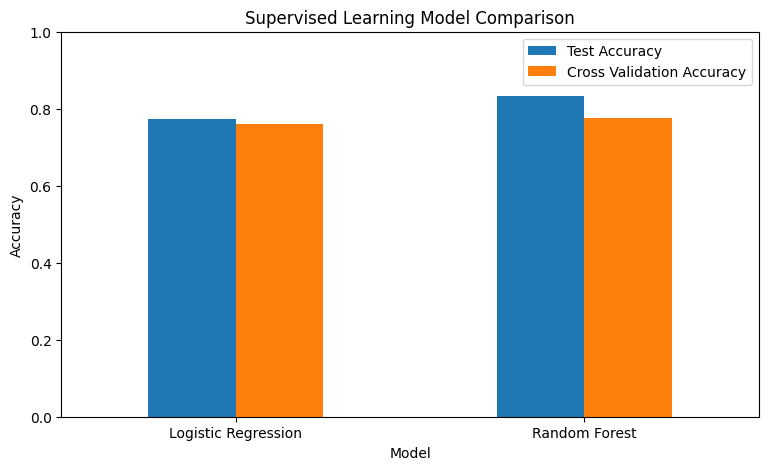

In [26]:
comparison.set_index('Model').plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Supervised Learning Model Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [27]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

display(importance)

,Feature,Importance
1,age,0.277644
4,fare,0.272027
5,sex_male,0.247346
0,pclass,0.088724
2,sibsp,0.049937
3,parch,0.035988
7,embarked_S,0.018983
6,embarked_Q,0.009350


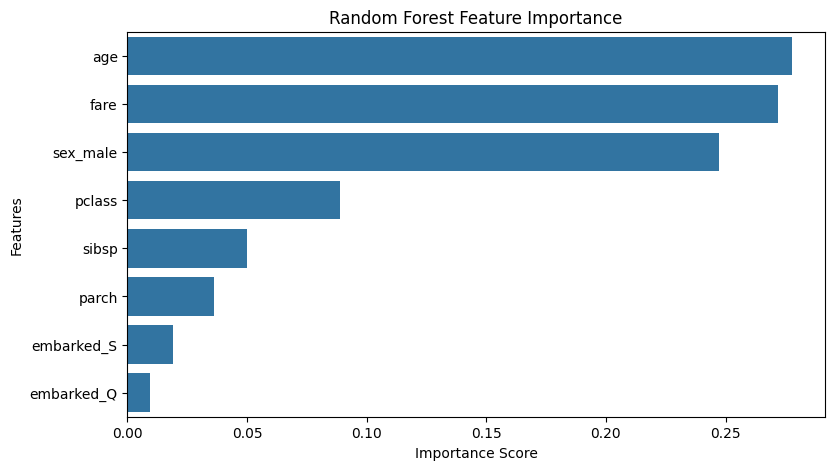

In [28]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.show()

In [29]:
print("FINAL MODEL PERFORMANCE")

print("Logistic Regression:")
print("Test Accuracy:", round(lr_accuracy * 100, 2), "%")
print("Cross Validation:", round(lr_cv_scores.mean() * 100, 2), "%")

print("\nRandom Forest:")
print("Test Accuracy:", round(rf_accuracy * 100, 2), "%")
print("Cross Validation:", round(rf_cv_scores.mean() * 100, 2), "%")

if lr_accuracy > rf_accuracy:
    print("\nLogistic Regression performed better on the test set.")
elif rf_accuracy > lr_accuracy:
    print("\nRandom Forest performed better on the test set.")
else:
    print("\nBoth models achieved equal test accuracy.")

FINAL MODEL PERFORMANCE
Logistic Regression:
Test Accuracy: 77.42 %
Cross Validation: 75.97 %

Random Forest:
Test Accuracy: 83.23 %
Cross Validation: 77.58 %

Random Forest performed better on the test set.
